In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:45951")
client

<Client: 'tcp://127.0.0.1:45951' processes=10 threads=40, memory=629.62 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
dsp = xr.open_zarr(op.join(ddir,"QG/eddy/qPsi.zarr"))
dsp

<xarray.Dataset> Size: 60GB
Dimensions:  (time: 718, level: 5, y: 1025, x: 2049)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
Data variables:
    pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
    qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>

In [5]:
N2 = xr.DataArray(np.array([4.04e-05, 1.6e-05, 1.24e-05, 2.52e-06,]), 
                  dims="li",
                  coords={"li":np.array([0.5,1.5,2.5,3.5])}
                 )
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":dsp.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(N2,Z,Zp1)

dsp["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                          coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                         )
dsp["Z"] = xr.DataArray(Z, dims="level",
                        coords={"level":dsp.level.data}
                       )
dsp["N2"] = N2

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
dsp.coords["yG"] = ("yG",.5*(dsp.y.data[1:]+dsp.y.data[:-1]))
dsp.coords["xG"] = ("xG",.5*(dsp.x.data[1:]+dsp.x.data[:-1]))

grid = Grid(dsp, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1", "inner": "li"}
                   })

dsp, grid

<xarray.DataArray (li: 4)> Size: 32B
array([4.04e-05, 1.60e-05, 1.24e-05, 2.52e-06])
Coordinates:
  * li       (li) float64 32B 0.5 1.5 2.5 3.5 [ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


(<xarray.Dataset> Size: 60GB
 Dimensions:  (time: 718, level: 5, y: 1025, x: 2049, lp1: 6, li: 4, yG: 1024,
               xG: 2048)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.856e+09 1.858e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
   * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
   * yG       (yG) float32 4kB 1.953e+03 5.859e+03 ... 3.994e+06 3.998e+06
   * xG       (xG) float32 8kB 1.953e+03 5.859e+03 ... 7.994e+06 7.998e+06
 Data variables:
     pp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
     qp       (time, level, y, x) float32 30GB dask.array<chunksize=(4, 1, 125, 256), meta=np.ndarray>
     Zp1      (lp1) float64 48B 0.0 -250.0 -500.0 -750.0 -1e+03 -4e+03
     Z        (level) 

In [6]:
Delta = 3.90625e+03
up = -(grid.diff(dsp.pp.fillna(0.).chunk({"y":-1}),
                 "Y",padding="extend") 
       / Delta)
vp = (grid.diff(dsp.pp.fillna(0.).chunk({"x":-1}),
                "X",padding="extend") 
      / Delta)
EKE = .5*(grid.interp(up**2,"Y",padding="extend") 
          + grid.interp(vp**2,"X",padding="extend")
         ).mean("time").compute()
EKE

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 31.92 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.DataArray 'pp' (level: 5, y: 1025, x: 2049)> Size: 42MB
array([[[0.0000000e+00, 0.0000000e+00, 1.7119834e-08, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        [0.0000000e+00, 1.6063055e-08, 1.2746108e-07, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        [1.5006275e-08, 1.1954309e-07, 6.3797017e-07, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        ...,
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         5.6199001e-10, 1.3737794e-10, 2.2324462e-11],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         1.3757880e-10, 2.2338425e-11, 0.0000000e+00],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         2.2352387e-11, 0.0000000e+00, 0.0000000e+00]],

       [[0.0000000e+00, 0.0000000e+00, 4.5087787e-09, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        [0.0000000e+00, 4.2722328e-09, 3.3776246e-08, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        [4.0356878e-09, 3.2000216e-08, 1.6852634e-07, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
...
         1.2737779e-09, 3.0444450e-10, 4.8426950e-11],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         3.1061456e-10, 4.9337773e-11, 0.0000000e+00],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         5.0248593e-11, 0.0000000e+00, 0.0000000e+00]],

       [[0.0000000e+00, 0.0000000e+00, 1.2261643e-09, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        [0.0000000e+00, 1.2086192e-09, 8.6392493e-09, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        [1.1910742e-09, 8.5168406e-09, 4.0238781e-08, ...,
         0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
        ...,
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         3.2804715e-09, 7.6159667e-10, 1.1804654e-10],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         7.8098250e-10, 1.2129080e-10, 0.0000000e+00],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         1.2453504e-10, 0.0000000e+00, 0.0000000e+00]]],
      shape=(5, 1025, 2049), dtype=float32)
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06

In [7]:
dsin = xr.open_dataset(op.join(ddir,"QG/input_vars_5l_N2048.nc")
                      ).isel(t=0)
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]
mask0_nan, mask0_c_nan

(array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]], shape=(1025, 2049)),
 array([[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]], shape=(1024, 2048)))

In [8]:
dsb = xr.open_zarr(op.join(ddir,"QG/mean/qPsi.zarr"))
dsb

<xarray.Dataset> Size: 84MB
Dimensions:  (level: 5, y: 1025, x: 2049)
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 4kB 0.0 3.906e+03 7.812e+03 ... 3.996e+06 4e+06
  * x        (x) float32 8kB 0.0 3.906e+03 7.812e+03 ... 7.996e+06 8e+06
Data variables:
    psi      (level, y, x) float32 42MB dask.array<chunksize=(1, 125, 256), meta=np.ndarray>
    q        (level, y, x) float32 42MB dask.array<chunksize=(1, 125, 256), meta=np.ndarray>

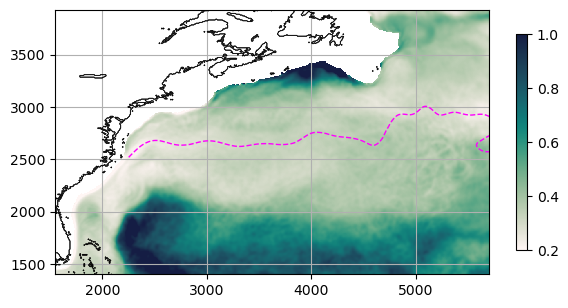

In [15]:
xmax = 5700
xmin = 1550
ymin = 1400
ymax = 3930

fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlim([xmin, xmax], )
ax.set_ylim([ymin, ymax], )

im = ax.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               EKE.isel(level=1)/EKE.isel(level=0), 
               cmap=cmocean.cm.tempo,
               # cmap="RdBu_r",
               vmin=0.2, vmax=1.,
               )

ax.contour(dsb.x*1e-3, dsb.y*1e-3, 
           dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
           levels=np.array([2.84e4,]), 
           colors="magenta", linestyles="dashed", linewidths=1
          )

ax.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax, shrink=.7)

ax.set_yticks([1500,2000,2500,3000,3500])
ax.set_xticks([2000,3000,4000,5000])

ax.grid(True)
ax.set_rasterized(True)
ax.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/EKE_QGratio2-1.pdf"))

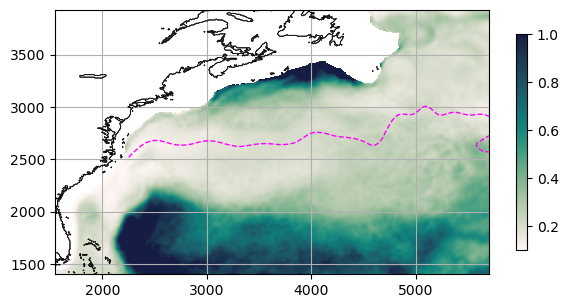

In [12]:
xmax = 5700
xmin = 1550
ymin = 1400
ymax = 3930

fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlim([xmin, xmax], )
ax.set_ylim([ymin, ymax], )

im = ax.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
               EKE.isel(level=2)/EKE.isel(level=0), 
               cmap=cmocean.cm.tempo,
               # cmap="RdBu_r",
               vmin=0.1, vmax=1.,
               )

ax.contour(dsb.x*1e-3, dsb.y*1e-3, 
           dsb.psi.where(dsb.y>2500e3).where(dsb.y<3200e3).isel(level=0), 
           levels=np.array([2.84e4,]), 
           colors="magenta", linestyles="dashed", linewidths=1
          )

ax.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax, shrink=.7)

ax.set_yticks([1500,2000,2500,3000,3500])
ax.set_xticks([2000,3000,4000,5000])

ax.grid(True)
ax.set_rasterized(True)
ax.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/EKE_QGratio3-1.pdf"))